# Color-only background removal (QS2)
One image, shown **before / after** each transformation. At the end: predicted mask vs ground truth.

In [14]:
import os
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ---- CONFIG: change these ----
DATA_DIR = Path().resolve().parent / 'data'
BBDD_DIR = DATA_DIR / 'BBDD'
QSD2 = DATA_DIR / 'qsd2_w2'
IMG_PATH = QSD2 / "00014.jpg"
GT_PATH  = QSD2 / "00014.png"   # ground-truth mask (white = painting)

BORDER = 10          # px strip used to model the background
BLUR_KSIZE = 15
PROJ_FRAC = 0.4      # (rect mode) row/col is "painting" if >50% of it is foreground
CHANNELS = [0, 1, 2]  # Lab channels used: 0 = L, 1 = a, 2 = b  (e.g. [0], [1, 2], [0, 2])
PREFILTER = "gauss"   # "none" | "gauss" | "median" | "bilateral"
MASK_MODE = "hull"   # "free" | "hull" | "rect"


In [15]:
def show_pair(before, after, t_before="Before", t_after="After", cmap_b=None, cmap_a=None, suptitle=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 6))
    ax[0].imshow(before, cmap=cmap_b); ax[0].set_title(t_before)
    ax[1].imshow(after, cmap=cmap_a);  ax[1].set_title(t_after)
    for a in ax: a.axis("off")
    if suptitle: fig.suptitle(suptitle, fontsize=14)
    plt.tight_layout(); plt.show()

def apply_prefilter(bgr, name):
    if name == "none":      return bgr
    if name == "gauss":     return cv2.GaussianBlur(bgr, (BLUR_KSIZE, BLUR_KSIZE), 0)
    if name == "median":    return cv2.medianBlur(bgr, BLUR_KSIZE)
    if name == "bilateral": return cv2.bilateralFilter(bgr, 9, 40, 9)
    raise ValueError(name)

rgb = lambda bgr: cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


## 0. Input image

shape: (580, 584, 3)


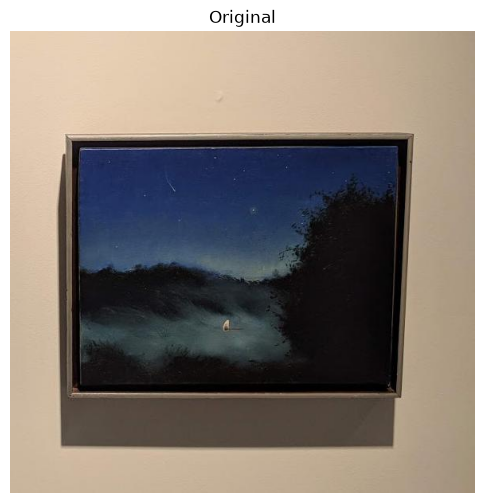

In [16]:
img = cv2.imread(IMG_PATH)
assert img is not None, f"Could not read {IMG_PATH}"
H, W = img.shape[:2]
print("shape:", img.shape)
plt.figure(figsize=(6, 7)); plt.imshow(rgb(img)); plt.axis("off"); plt.title("Original"); plt.show()


## 1. Preprocessing filter (`PREFILTER`)
Smooths texture / noise so the color statistics are cleaner. Set `PREFILTER = "none"` to skip it.

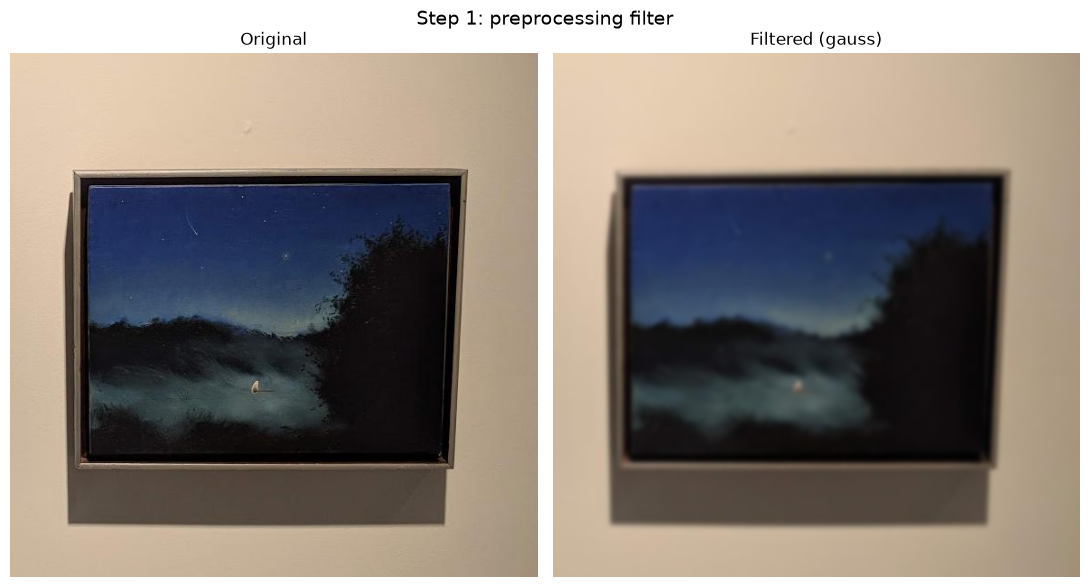

In [17]:
blur = apply_prefilter(img, PREFILTER)
show_pair(rgb(img), rgb(blur), "Original", f"Filtered ({PREFILTER})", suptitle="Step 1: preprocessing filter")


## 2. Color space: BGR → Lab
Shown as the three Lab channels (L = lightness, a / b = chroma).

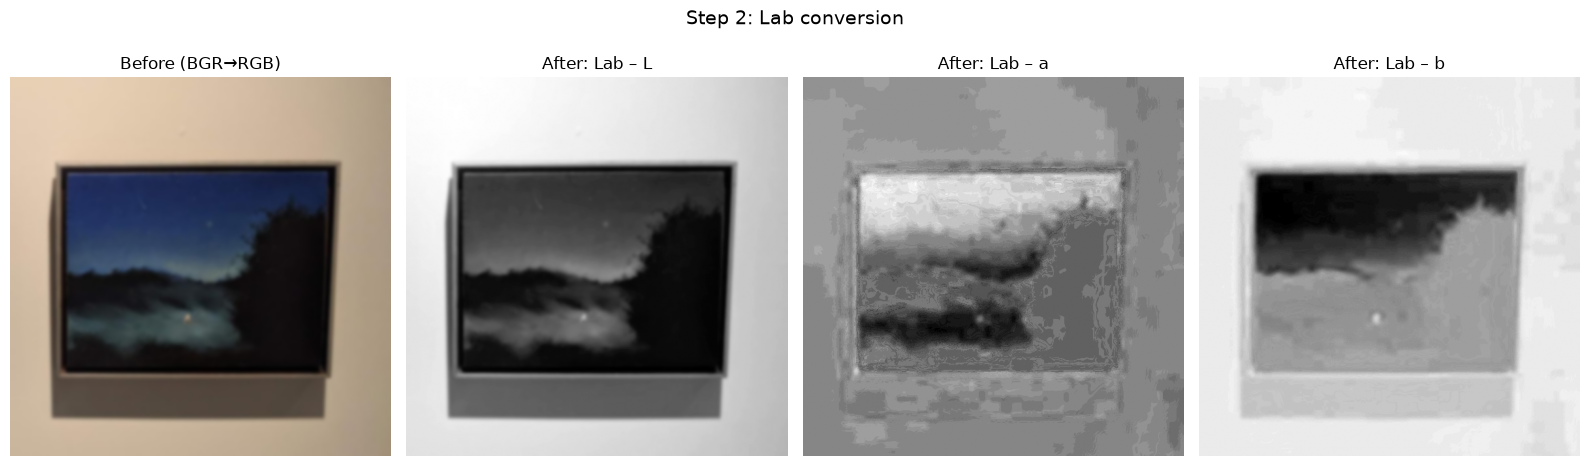

In [18]:
lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB)
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
ax[0].imshow(rgb(blur)); ax[0].set_title("Before (BGR→RGB)")
for i, n in enumerate(["L", "a", "b"]):
    ax[i + 1].imshow(lab[..., i], cmap="gray"); ax[i + 1].set_title(f"After: Lab – {n}")
for a in ax: a.axis("off")
fig.suptitle("Step 2: Lab conversion", fontsize=14); plt.tight_layout(); plt.show()


## 3. Background model from the border strip
Median color + robust covariance of the 10 px frame around the image.

Channels used: ['L', 'a', 'b']
Background median: [191. 131. 143.]
Background covariance:
 [[3.0909e+02 9.6100e+00 1.1790e+01]
 [9.6100e+00 1.7300e+00 1.3000e-01]
 [1.1790e+01 1.3000e-01 2.0200e+00]]


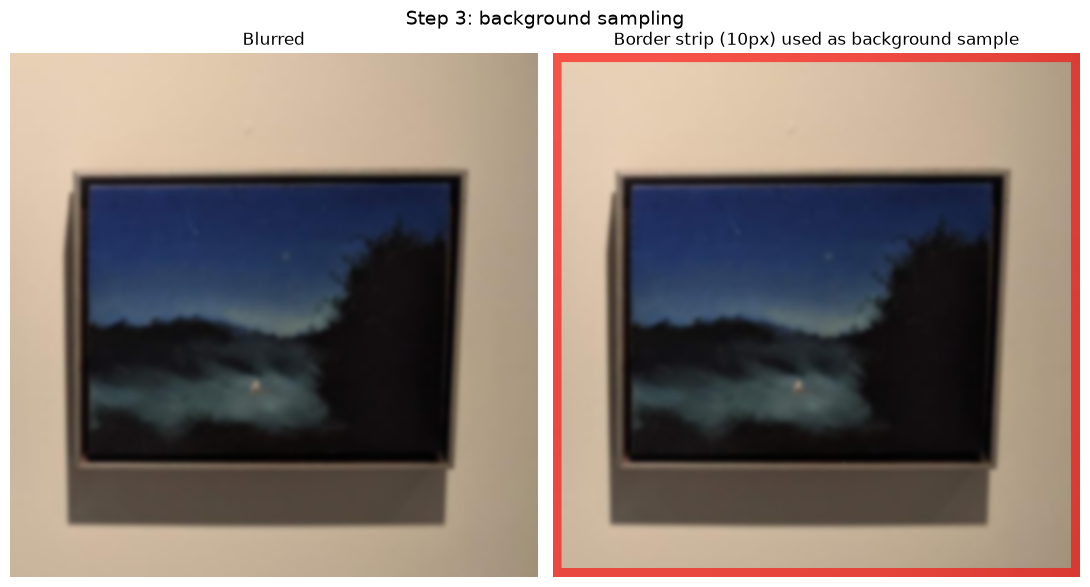

In [19]:
def border_mask(h, w, b=BORDER):
    m = np.zeros((h, w), bool)
    m[:b] = m[h - b:] = True
    m[:, :b] = m[:, w - b:] = True
    return m

bm = border_mask(H, W)
px = lab[bm][:, CHANNELS].astype(np.float32)
med = np.median(px, axis=0)
d = np.linalg.norm(px - med, axis=1)
inliers = px[d < np.percentile(d, 90)]          # drop outliers (labels, shadows)
cov = np.atleast_2d(np.cov(inliers.T)) + np.eye(len(CHANNELS))             # regularised
icov = np.linalg.inv(cov)
print("Channels used:", [ "Lab"[i] for i in CHANNELS ])
print("Background median:", med)
print("Background covariance:\n", np.round(cov, 2))

overlay = rgb(blur).copy()
overlay[bm] = (0.4 * overlay[bm] + 0.6 * np.array([255, 0, 0])).astype(np.uint8)
show_pair(rgb(blur), overlay, "Blurred", f"Border strip ({BORDER}px) used as background sample",
          suptitle="Step 3: background sampling")


## 4. Distance to the background model (Mahalanobis)

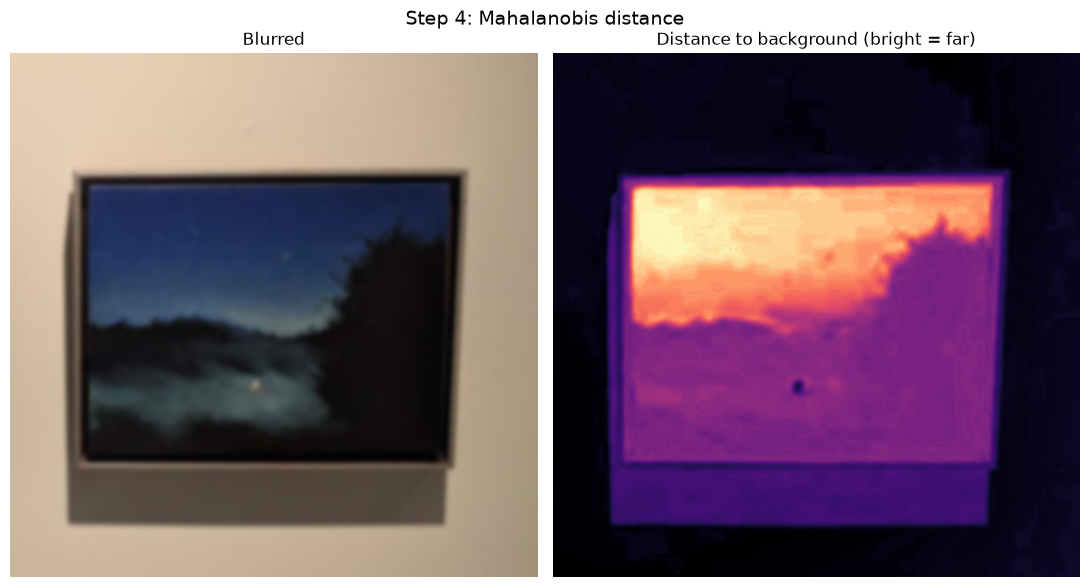

In [20]:
diff = lab.reshape(-1, 3)[:, CHANNELS].astype(np.float32) - med
dist = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", diff, icov, diff), 0)).reshape(H, W)
dist_u8 = cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show_pair(rgb(blur), dist_u8, "Blurred", "Distance to background (bright = far)",
          cmap_a="magma", suptitle="Step 4: Mahalanobis distance")


## 5. Otsu threshold → raw foreground mask

Otsu threshold: 122.0


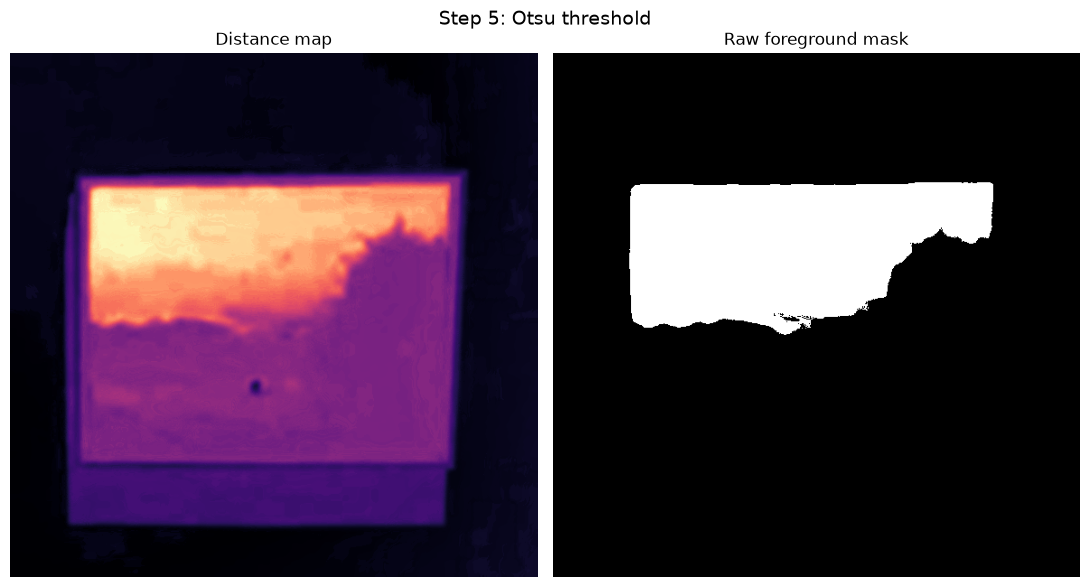

In [21]:
t, fg_raw = cv2.threshold(dist_u8, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold:", t)
show_pair(dist_u8, fg_raw, "Distance map", "Raw foreground mask",
          cmap_b="magma", cmap_a="gray", suptitle="Step 5: Otsu threshold")


## 6. Morphological clean-up
Close fills holes inside the painting; open removes small blobs (e.g. the wall label).

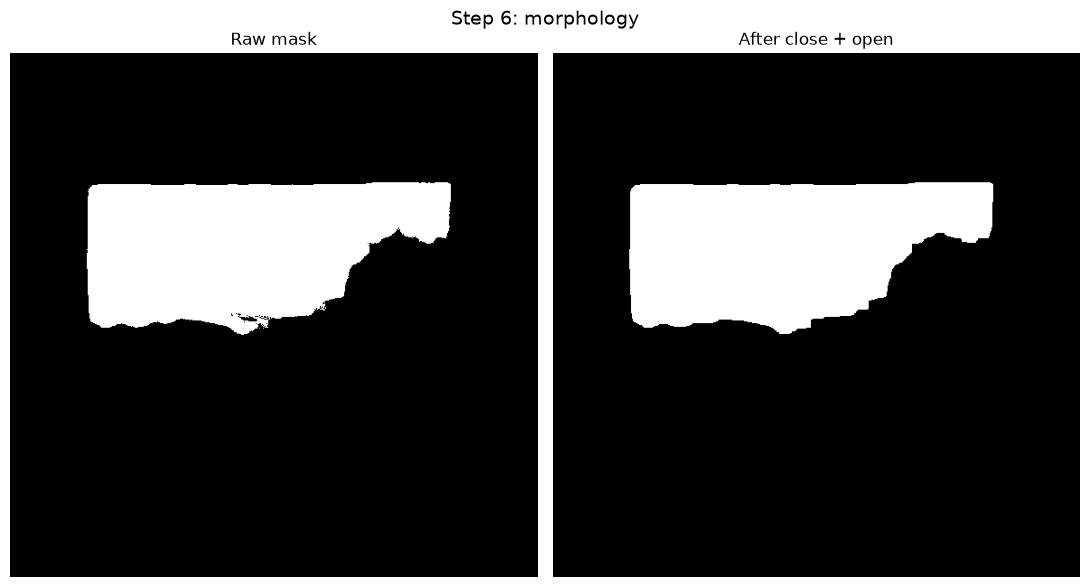

In [22]:
k = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
fg_clean = cv2.morphologyEx(fg_raw, cv2.MORPH_CLOSE, k)
fg_clean = cv2.morphologyEx(fg_clean, cv2.MORPH_OPEN, k)
show_pair(fg_raw, fg_clean, "Raw mask", "After close + open", "gray", "gray",
          suptitle="Step 6: morphology")


## 7. Final mask shape
Three options, all color-only (no edge / contour detection). Pick one with `MASK_MODE` in the config cell:
- `free`: the cleaned color mask itself (holes filled, largest blob kept) – follows any shape
- `hull`: convex hull of that mask – straight edges, diagonals and skewed corners allowed
- `rect`: axis-aligned rectangle from row/column projections

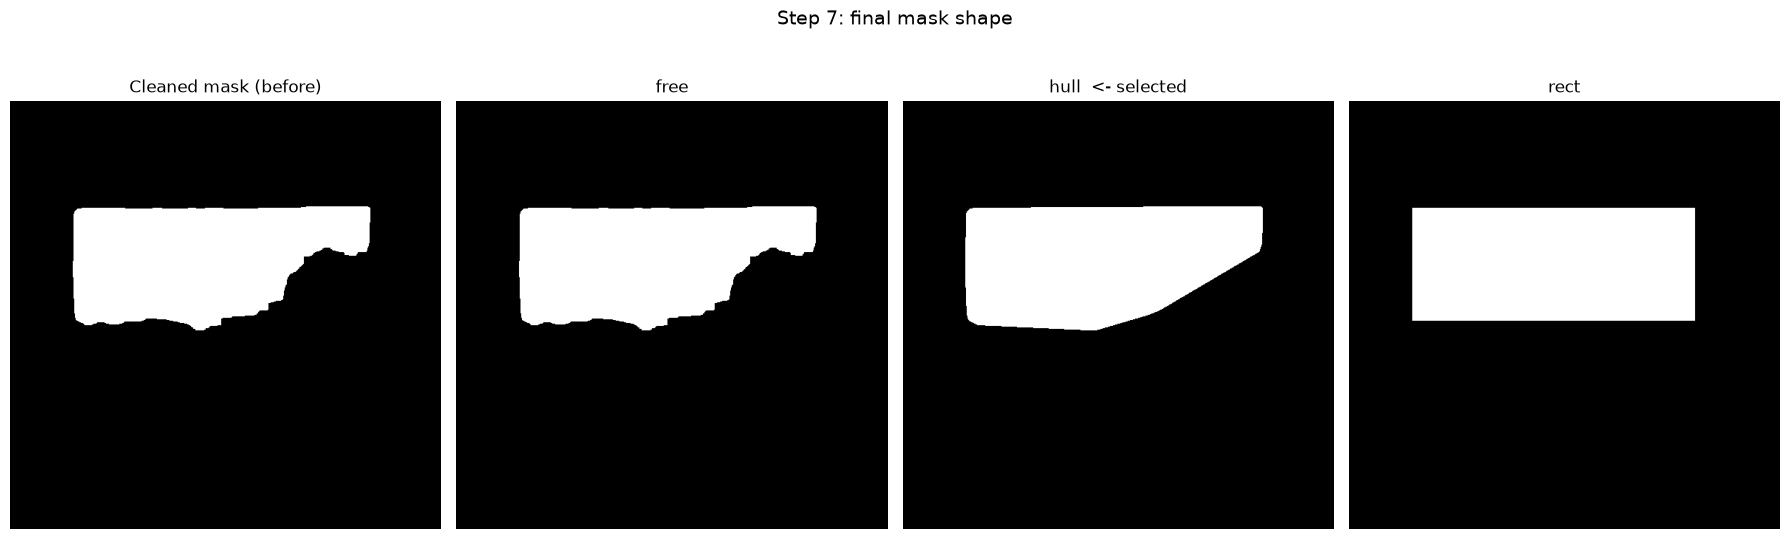

In [23]:
# --- free shape: fill holes + keep the largest blob ---
filled = fg_clean.copy()
ff = filled.copy()
cv2.floodFill(ff, np.zeros((H + 2, W + 2), np.uint8), (0, 0), 2)   # corner = background
filled[ff != 2] = 1                                                # anything not reached is painting
n, lab_cc, stats, _ = cv2.connectedComponentsWithStats(filled, connectivity=8)
if n < 2:   # nothing detected -> fall back to the whole image so the notebook keeps running
    print("WARNING: no foreground found; using full image as the mask. Check the distance map / threshold.")
    mask_free = np.ones((H, W), np.uint8)
else:
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    mask_free = (lab_cc == largest).astype(np.uint8)

# --- hull: convex hull of the foreground pixels ---
pts = np.column_stack(np.where(mask_free)[::-1]).astype(np.int32)   # (x, y)
hull = cv2.convexHull(pts)
mask_hull = np.zeros((H, W), np.uint8)
cv2.fillConvexPoly(mask_hull, hull, 1)

# --- rect: bounding box from projections ---
# threshold relative to the strongest row/column, so small paintings still work
col_prof, row_prof = mask_free.mean(axis=0), mask_free.mean(axis=1)
cols = col_prof > PROJ_FRAC * col_prof.max()
rows = row_prof > PROJ_FRAC * row_prof.max()
x0, x1 = np.where(cols)[0][[0, -1]]
y0, y1 = np.where(rows)[0][[0, -1]]
mask_rect = np.zeros((H, W), np.uint8)
mask_rect[y0:y1 + 1, x0:x1 + 1] = 1

masks = {"free": mask_free, "hull": mask_hull, "rect": mask_rect}
pred = masks[MASK_MODE]

fig, ax = plt.subplots(1, 4, figsize=(18, 6))
ax[0].imshow(fg_clean, cmap="gray"); ax[0].set_title("Cleaned mask (before)")
for a_, (name, m) in zip(ax[1:], masks.items()):
    a_.imshow(m, cmap="gray"); a_.set_title(f"{name}" + ("  <- selected" if name == MASK_MODE else ""))
for a_ in ax: a_.axis("off")
fig.suptitle("Step 7: final mask shape", fontsize=14); plt.tight_layout(); plt.show()


## 8. Result: foreground extracted with the predicted mask

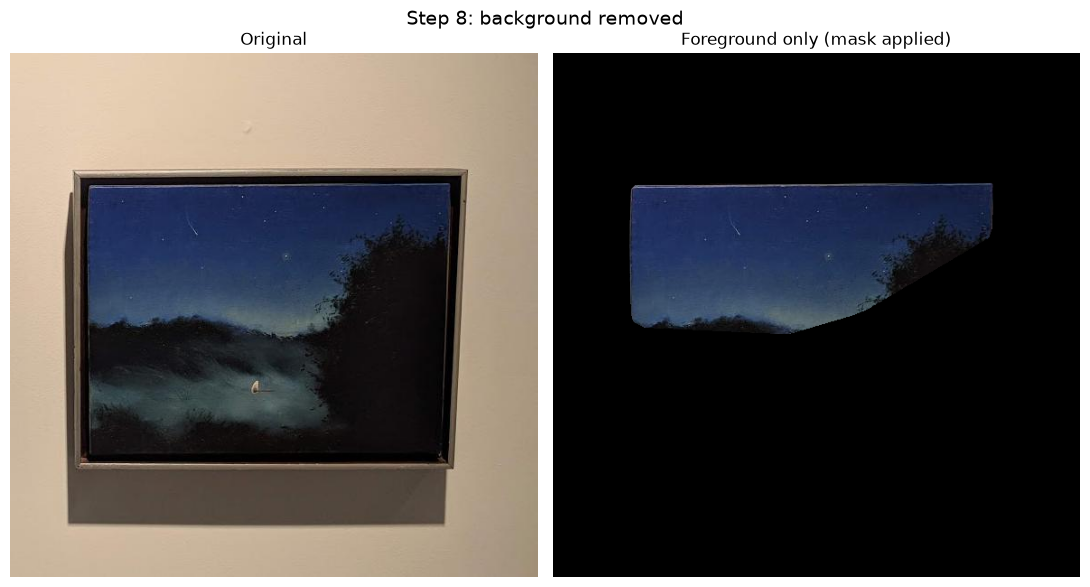

In [24]:
result = img.copy(); result[pred == 0] = 0
show_pair(rgb(img), rgb(result), "Original", "Foreground only (mask applied)", suptitle="Step 8: background removed")


## 9. Predicted mask vs ground truth
Overlay colors: **green** = true positive, **red** = false positive (predicted but not painting), **blue** = false negative (missed painting).

[hull] Precision: 1.0000   Recall: 0.3928   F1: 0.5640
  free  P=1.0000  R=0.3585  F1=0.5277
  hull  P=1.0000  R=0.3928  F1=0.5640
  rect  P=1.0000  R=0.4119  F1=0.5835


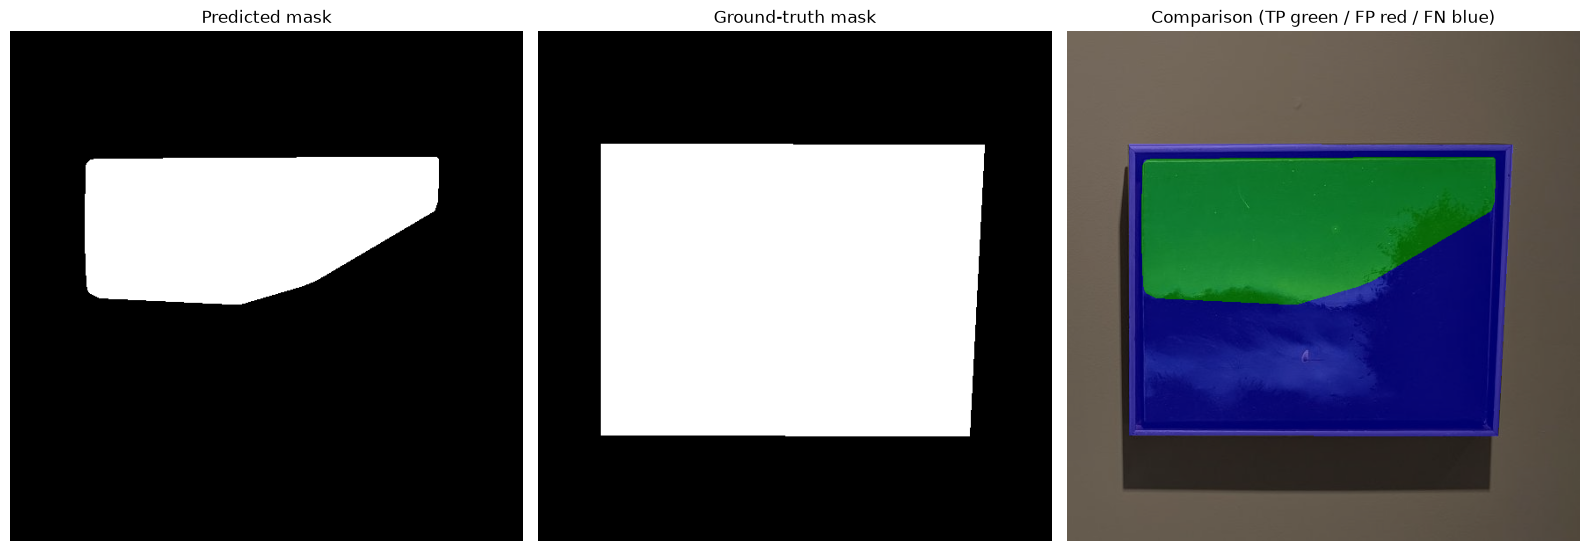

In [25]:
def evaluate(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
    return p, r, 2 * p * r / (p + r + 1e-9)

if os.path.exists(GT_PATH):
    gt = (cv2.imread(GT_PATH, 0) > 127).astype(np.uint8)
    if gt.shape != pred.shape:
        gt = cv2.resize(gt, (W, H), interpolation=cv2.INTER_NEAREST)

    p, r, f1 = evaluate(pred, gt)
    print(f"[{MASK_MODE}] Precision: {p:.4f}   Recall: {r:.4f}   F1: {f1:.4f}")
    for name, m in masks.items():
        pp, rr, ff1 = evaluate(m, gt)
        print(f"  {name:5s} P={pp:.4f}  R={rr:.4f}  F1={ff1:.4f}")

    diffimg = np.zeros((H, W, 3), np.uint8)
    diffimg[(pred == 1) & (gt == 1)] = (0, 200, 0)
    diffimg[(pred == 1) & (gt == 0)] = (220, 0, 0)
    diffimg[(pred == 0) & (gt == 1)] = (0, 0, 220)

    fig, ax = plt.subplots(1, 3, figsize=(16, 7))
    ax[0].imshow(pred, cmap="gray"); ax[0].set_title("Predicted mask")
    ax[1].imshow(gt, cmap="gray");   ax[1].set_title("Ground-truth mask")
    ax[2].imshow(rgb(img)); ax[2].imshow(diffimg, alpha=0.5); ax[2].set_title("Comparison (TP green / FP red / FN blue)")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print(f"Ground truth not found at {GT_PATH} – set GT_PATH to compare. Showing the prediction only.")
    show_pair(rgb(img), pred, "Original", "Predicted mask", cmap_a="gray")


## 10. Ablation: which Lab channels and which prefilter?
Runs the whole pipeline (hull mode) for every combination and reports F1 against the ground truth. Use several images for conclusions; one image can be misleading.

F1 (rows = prefilter, cols = channels)
               L       a       b     a+b     L+a     L+b   L+a+b
none       0.897   0.433   0.563   0.570   0.898   0.561   0.567
gauss      0.899   0.372   0.572   0.568   0.899   0.564   0.564
median     0.896   0.395   0.560   0.561   0.895   0.558   0.561
bilateral  0.897   0.392   0.563   0.565   0.896   0.562   0.563


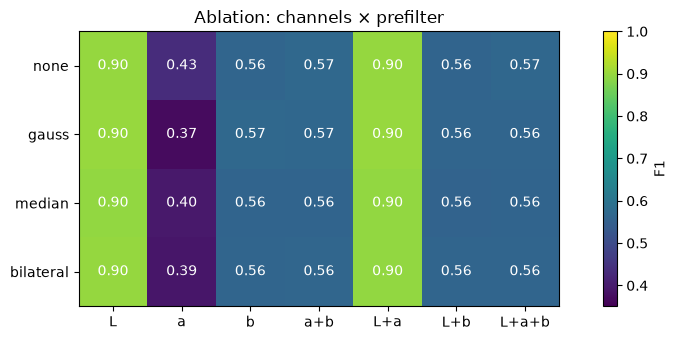

In [26]:
def run_pipeline(bgr, channels, filt):
    h, w = bgr.shape[:2]
    lab_ = cv2.cvtColor(apply_prefilter(bgr, filt), cv2.COLOR_BGR2LAB)[..., channels].astype(np.float32)
    bm_ = border_mask(h, w)
    px_ = lab_[bm_]
    med_ = np.median(px_, axis=0)
    d_ = np.linalg.norm(px_ - med_, axis=1)
    inl = px_[d_ < np.percentile(d_, 90)]
    ic = np.linalg.inv(np.atleast_2d(np.cov(inl.T)) + np.eye(len(channels)))
    df = lab_.reshape(-1, len(channels)) - med_
    dist_ = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", df, ic, df), 0)).reshape(h, w)
    u8 = cv2.normalize(dist_, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, fg = cv2.threshold(u8, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kk = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    fg = cv2.morphologyEx(cv2.morphologyEx(fg, cv2.MORPH_CLOSE, kk), cv2.MORPH_OPEN, kk)
    f = fg.copy(); cv2.floodFill(f, np.zeros((h + 2, w + 2), np.uint8), (0, 0), 2); fg[f != 2] = 1
    n_, l_, st_, _ = cv2.connectedComponentsWithStats(fg, connectivity=8)
    if n_ < 2:
        return np.ones((h, w), np.uint8)
    m_ = (l_ == 1 + np.argmax(st_[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    hull_ = cv2.convexHull(np.column_stack(np.where(m_)[::-1]).astype(np.int32))
    out = np.zeros((h, w), np.uint8); cv2.fillConvexPoly(out, hull_, 1)
    return out

if os.path.exists(GT_PATH):
    chan_sets = {"L": [0], "a": [1], "b": [2], "a+b": [1, 2], "L+a": [0, 1], "L+b": [0, 2], "L+a+b": [0, 1, 2]}
    filters = ["none", "gauss", "median", "bilateral"]
    table = np.array([[evaluate(run_pipeline(img, c, f), gt)[2] for c in chan_sets.values()] for f in filters])

    print("F1 (rows = prefilter, cols = channels)")
    print("          " + "  ".join(f"{k:>6s}" for k in chan_sets))
    for f, row in zip(filters, table):
        print(f"{f:10s}" + "  ".join(f"{v:6.3f}" for v in row))

    plt.figure(figsize=(9, 3.5))
    plt.imshow(table, cmap="viridis", vmin=max(0, table.min() - 0.02), vmax=1)
    plt.xticks(range(len(chan_sets)), chan_sets.keys()); plt.yticks(range(len(filters)), filters)
    for i in range(len(filters)):
        for j in range(len(chan_sets)):
            plt.text(j, i, f"{table[i, j]:.2f}", ha="center", va="center", color="w")
    plt.colorbar(label="F1"); plt.title("Ablation: channels × prefilter"); plt.tight_layout(); plt.show()
else:
    print("Ablation needs a ground-truth mask (set GT_PATH).")
